# Partie 8 — Analyse des résultats

Ce notebook **lit uniquement** les fichiers CSV de résultats ; il ne génère ni ne modifie aucune donnée. Il résume les 33 configurations échantillonnées, utilise un petit arbre de décision pour décrire les tendances et analyse une comparaison contrôlée des plages, enregistrée séparément. Les conclusions s'appliquent à ces expériences, et non à tous les programmes ou à toutes les machines.

Pour reproduire l'analyse, installez les dépendances avec `pip install -r requirements-analysis.txt`, puis exécutez toutes les cellules depuis `tp3/` ou ouvrez ce notebook dans VS Code/Jupyter. L'expérience contrôlée se lance séparément avec `run_sample.py` ; ce notebook ne l'exécute pas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, export_text

candidates = [Path.cwd(), Path.cwd() / "tp3"]
ROOT = next((path for path in candidates if (path / "configs/results.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Impossible de trouver configs/results.csv ; ouvrez le notebook depuis tp3/ ou la racine du dépôt.")

results = pd.read_csv(ROOT / "configs/results.csv")
causal = pd.read_csv(ROOT / "configs/causal-range-results.csv")
required = {
    "config_id", "origin_of_config", "Language", "Implementation", "Property",
    "NumberType", "Repetitions", "RandomSeed", "NumberRange", "UpperBound",
    "run_index", "effective_repetitions", "actual_seed", "effective_min",
    "effective_max", "effective_upper_bound", "answer_equal_count", "answer_percentage",
}
missing = required - set(results.columns)
if missing:
    raise ValueError(f"Le CSV principal ne contient pas les colonnes suivantes : {sorted(missing)}")
if results.empty or causal.empty:
    raise ValueError("Les fichiers CSV de résultats ne doivent pas être vides.")

results.head()

,config_id,origin_of_config,Language,Implementation,Property,NumberType,Repetitions,RandomSeed,NumberRange,UpperBound,...,effective_min,effective_max,effective_upper_bound,answer_equal_count,answer_percentage,random_generator,runtime_version,platform,command,duration_seconds
0,tp1_original,anchor,Java,Original,AdditionAssociativity,Double,Tests_100M,Seed_NotDocumented,Range_UnitInterval,Exclusive,...,0.000000e+00,1.000000e+00,exclusive,82815193,82.815193,java.util.Random,"openjdk version ""25.0.4.1"" 2026-08-18",Linux-7.0.0-43-generic-x86_64-with-glibc2.43,"[""java"", ""-cp"", ""/home/grevyr/Documents/INSA/r...",9.128884
1,tp1_original,anchor,Java,Original,AdditionAssociativity,Double,Tests_100M,Seed_NotDocumented,Range_UnitInterval,Exclusive,...,0.000000e+00,1.000000e+00,exclusive,82819307,82.819307,java.util.Random,"openjdk version ""25.0.4.1"" 2026-08-18",Linux-7.0.0-43-generic-x86_64-with-glibc2.43,"[""java"", ""-cp"", ""/home/grevyr/Documents/INSA/r...",9.189168
2,tp1_original,anchor,Java,Original,AdditionAssociativity,Double,Tests_100M,Seed_NotDocumented,Range_UnitInterval,Exclusive,...,0.000000e+00,1.000000e+00,exclusive,82821278,82.821278,java.util.Random,"openjdk version ""25.0.4.1"" 2026-08-18",Linux-7.0.0-43-generic-x86_64-with-glibc2.43,"[""java"", ""-cp"", ""/home/grevyr/Documents/INSA/r...",9.151667
3,tp2_llm_python,anchor,Python,LLMGenerated,AdditionAssociativity,Double,Tests_1M,Seed_42,Range_Symmetric_1e16,Inclusive,...,-1.000000e+16,1.000000e+16,inclusive,924657,92.465700,NumPy MT19937,Python 3.14.4 / NumPy 2.3.5,Linux-7.0.0-43-generic-x86_64-with-glibc2.43,"[""/home/grevyr/Documents/INSA/reproductibilite...",0.302015
4,tp2_llm_python,anchor,Python,LLMGenerated,AdditionAssociativity,Double,Tests_1M,Seed_42,Range_Symmetric_1e16,Inclusive,...,-1.000000e+16,1.000000e+16,inclusive,924401,92.440100,NumPy MT19937,Python 3.14.4 / NumPy 2.3.5,Linux-7.0.0-43-generic-x86_64-with-glibc2.43,"[""/home/grevyr/Documents/INSA/reproductibilite...",0.287244


## Couverture et unité d'analyse

Les trois exécutions d'une même configuration ne constituent pas trois configurations indépendantes. Nous calculons d'abord la moyenne par `config_id` ; l'étude des facteurs utilise ces moyennes pour ne pas compter chaque configuration trois fois. L'écart entre les exécutions d'une configuration mesure la variation observée entre les graines testées.

In [2]:
factors = [
    "Language", "Implementation", "Property", "NumberType", "Repetitions",
    "RandomSeed", "NumberRange", "UpperBound",
]
metadata = [column for column in factors + ["origin_of_config"] if column in results.columns]
config_summary = results.groupby("config_id", as_index=False).agg(
    answer_mean=("answer_percentage", "mean"),
    answer_sd=("answer_percentage", "std"),
    answer_min=("answer_percentage", "min"),
    answer_max=("answer_percentage", "max"),
    run_count=("run_index", "count"),
)
config_summary = config_summary.merge(results.groupby("config_id")[metadata].first(), on="config_id")
config_summary["answer_sd"] = config_summary["answer_sd"].fillna(0)
stability = results.groupby("config_id").agg(
    run_sd_pp=("answer_percentage", "std"),
    repetitions=("Repetitions", "first"),
)

print(f"{len(results)} exécutions ; {len(config_summary)} configurations")
print("Nombre d'exécutions par configuration :", sorted(config_summary["run_count"].unique()))
print("Plateformes :", results["platform"].nunique() if "platform" in results else "non renseignée")
print("Versions recensées :", sorted(results["runtime_version"].dropna().unique()) if "runtime_version" in results else "non renseignées")
print(f"Écart-type entre les exécutions (médiane) : {config_summary['answer_sd'].median():.4f} point de pourcentage")
display(stability.groupby("repetitions")["run_sd_pp"].agg(
    configurations="count", median_run_sd_pp="median", max_run_sd_pp="max"
).round(4))
config_summary.sort_values("answer_mean").head()

99 exécutions ; 33 configurations
Nombre d'exécutions par configuration : [np.int64(3)]
Plateformes : 1
Versions recensées : ['Python 3.14.4 / NumPy 2.3.5', 'openjdk version "25.0.4.1" 2026-08-18']
Écart-type entre les exécutions (médiane) : 0.0058 point de pourcentage


,configurations,median_run_sd_pp,max_run_sd_pp
repetitions,,,
Tests_100M,15,0.0031,0.0063
Tests_1M,18,0.0186,0.0620


,config_id,answer_mean,answer_sd,answer_min,answer_max,run_count,Language,Implementation,Property,NumberType,Repetitions,RandomSeed,NumberRange,UpperBound,origin_of_config
3,r04,52.822433,0.021195,52.809700,52.846900,3,Python,LLMGenerated,Distributivity,Float,Tests_1M,Seed_123,Range_NotDocumented,NotDocumented,random
6,r07,52.824767,0.010456,52.817900,52.836800,3,Java,LLMGenerated,Distributivity,Float,Tests_1M,Seed_123,Range_NotDocumented,Inclusive,random
1,r02,58.285121,0.006338,58.277924,58.289869,3,Java,Original,Distributivity,Double,Tests_100M,Seed_123,Range_Symmetric_1e16,Inclusive,random
28,r29,58.307500,0.015962,58.291200,58.323100,3,Java,Original,Distributivity,Double,Tests_1M,Seed_123,Range_Symmetric_1e16,Exclusive,random
21,r22,58.366367,0.058199,58.323400,58.432600,3,Python,LLMGenerated,Distributivity,Double,Tests_1M,Seed_42,Range_Symmetric_1e16,Exclusive,random


La couverture actuelle est limitée : 33 configurations, trois graines par configuration, une plateforme (Linux x86-64) et les versions locales consignées (Python 3.14.4/NumPy 2.3.5 et OpenJDK 25.0.4.1). Ce CSV ne permet donc pas d'estimer l'effet de l'architecture, de la version ou de l'environnement d'exécution, même si le workflow CI prévoit une matrice.

In [3]:
factor_tables = {}
for factor in factors:
    table = (config_summary.groupby(factor)["answer_mean"]
             .agg(configurations="count", mean="mean", median="median", sd="std")
             .sort_values("mean", ascending=False))
    factor_tables[factor] = table
    print(f"\n{factor} — pourcentage moyen d'égalités par configuration")
    display(table.round(3))

factor_spans = pd.DataFrame([
    {
        "factor": factor,
        "levels": config_summary[factor].nunique(),
        "largest_observed_gap_pp": (
            config_summary.groupby(factor)["answer_mean"].mean().max()
            - config_summary.groupby(factor)["answer_mean"].mean().min()
        ),
    }
    for factor in factors
]).sort_values("largest_observed_gap_pp", ascending=False)
display(factor_spans.round(3))


Language — pourcentage moyen d'égalités par configuration


,configurations,mean,median,sd
Language,,,,
Java,22,76.206,68.938,15.687
Python,11,75.122,67.384,17.405



Implementation — pourcentage moyen d'égalités par configuration


,configurations,mean,median,sd
Implementation,,,,
LLMGenerated,20,78.249,71.755,17.168
Original,13,72.147,67.374,13.879



Property — pourcentage moyen d'égalités par configuration


,configurations,mean,median,sd
Property,,,,
MultiplicationAssociativity,13,81.249,65.224,18.069
AdditionAssociativity,12,80.288,78.694,11.561
Distributivity,8,60.400,58.337,6.461


... (7 outputs left out)

,configurations,mean,median,sd
NumberRange,,,,
Range_Symmetric_1e16,15,80.649,92.378,17.675
Range_NotDocumented,10,73.210,67.391,17.793
Range_UnitInterval,8,70.131,67.048,6.604



UpperBound — pourcentage moyen d'égalités par configuration


,configurations,mean,median,sd
UpperBound,,,,
Inclusive,12,80.215,80.657,18.681
Exclusive,11,78.175,74.570,14.730
NotDocumented,10,68.038,65.182,12.011


,factor,levels,largest_observed_gap_pp
2,Property,3,20.849
7,UpperBound,3,12.177
6,NumberRange,3,10.518
5,RandomSeed,3,9.384
1,Implementation,2,6.102
3,NumberType,2,4.934
4,Repetitions,2,4.791
0,Language,2,1.085


Ces moyennes représentent des **associations non ajustées** : l'échantillonnage n'équilibre pas toutes les combinaisons et les facteurs peuvent être liés (par exemple, `Range_NotDocumented` est déterminé en fonction de `Implementation`). Elles ne doivent pas être interprétées comme l'effet causal isolé de chaque facteur.

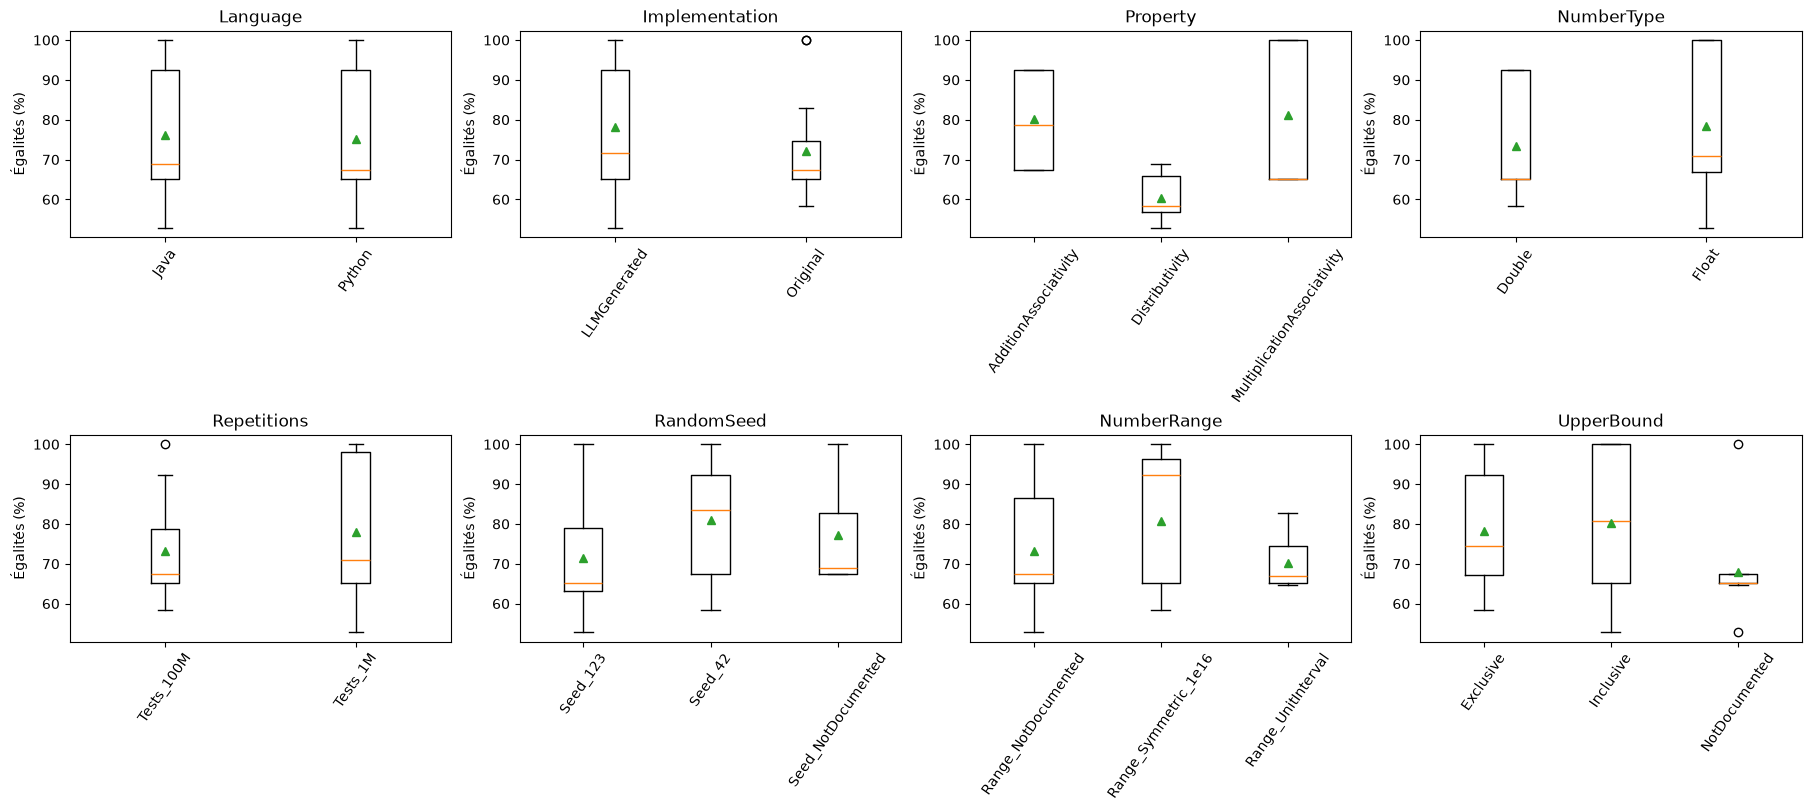

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
for ax, factor in zip(axes.flat, factors):
    groups = [part["answer_mean"].to_numpy() for _, part in config_summary.groupby(factor, sort=True)]
    labels = [str(value) for value in sorted(config_summary[factor].dropna().unique())]
    ax.boxplot(groups, tick_labels=labels, showmeans=True)
    ax.set_title(factor)
    ax.set_ylabel("Égalités (%)")
    ax.tick_params(axis="x", labelrotation=55)
plt.show()

## Arbre interprétable (descriptif)

L'arbre prédit le pourcentage moyen par configuration à partir des facteurs catégoriels. Sa profondeur est volontairement limitée à 3 et chaque feuille doit contenir au moins 3 configurations afin de rendre les règles lisibles. Il résume les tendances de ce petit échantillon ; ce n'est ni une preuve causale ni un modèle validé pour prédire de nouvelles configurations.

In [5]:
model_factors = [factor for factor in factors if factor in config_summary]
X = pd.get_dummies(config_summary[model_factors].astype("string"), dtype=int)
tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=3, random_state=0)
tree.fit(X, config_summary["answer_mean"])
print(export_text(tree, feature_names=list(X.columns), decimals=2))
importance = pd.Series(tree.feature_importances_, index=X.columns)
display(importance[importance > 0].sort_values(ascending=False).to_frame("importance dans cet arbre"))

|--- Property_Distributivity <= 0.50
|   |--- UpperBound_NotDocumented <= 0.50
|   |   |--- NumberRange_Range_Symmetric_1e16 <= 0.50
|   |   |   |--- value: [77.76]
|   |   |--- NumberRange_Range_Symmetric_1e16 >  0.50
|   |   |   |--- value: [92.76]
|   |--- UpperBound_NotDocumented >  0.50
|   |   |--- Repetitions_Tests_1M <= 0.50
|   |   |   |--- value: [66.05]
|   |   |--- Repetitions_Tests_1M >  0.50
|   |   |   |--- value: [77.53]
|--- Property_Distributivity >  0.50
|   |--- Repetitions_Tests_100M <= 0.50
|   |   |--- value: [55.58]
|   |--- Repetitions_Tests_100M >  0.50
|   |   |--- value: [65.22]



,importance dans cet arbre
Property_Distributivity,0.485826
UpperBound_NotDocumented,0.246930
NumberRange_Range_Symmetric_1e16,0.183789
Repetitions_Tests_1M,0.047618
Repetitions_Tests_100M,0.035837


Dans cet échantillon, la propriété distingue assez bien les pourcentages : l'associativité de l'addition ou de la multiplication donne généralement des valeurs supérieures à la distributivité. C'est cohérent, car les égalités évaluées sont différentes ; cela ne signifie pas qu'une propriété est « plus correcte ». La plage, la précision (`Float`/`Double`) et l'expression évaluée influencent l'arrondi et la probabilité que les deux membres donnent exactement la même valeur. Il faut interpréter le sens et l'ampleur de ces écarts à partir des tableaux, et non considérer l'importance dans l'arbre comme un effet causal.

## Résultats des laboratoires 1 et 2

Les trois configurations de référence permettent de replacer les résultats observés dans leur contexte. La valeur est la moyenne des trois exécutions de chaque référence. La comparaison entre ces références n'isole pas un seul facteur.

In [6]:
anchors = (config_summary[config_summary["origin_of_config"] == "anchor"]
           .sort_values("config_id"))
anchor_columns = [c for c in ["config_id", "Language", "Implementation", "Property", "NumberType",
                              "Repetitions", "NumberRange", "UpperBound", "answer_mean", "answer_sd"]
                  if c in anchors]
display(anchors[anchor_columns].round(5))

,config_id,Language,Implementation,Property,NumberType,Repetitions,NumberRange,UpperBound,answer_mean,answer_sd
30,tp1_original,Java,Original,AdditionAssociativity,Double,Tests_100M,Range_UnitInterval,Exclusive,82.81859,0.00310
31,tp2_llm_python,Python,LLMGenerated,AdditionAssociativity,Double,Tests_1M,Range_Symmetric_1e16,Inclusive,92.43393,0.03526
32,tp3_llm_java,Java,LLMGenerated,AdditionAssociativity,Double,Tests_1M,Range_Symmetric_1e16,Exclusive,92.38477,0.03504


Le résultat du laboratoire 1 était de **82.815267 %** : Java `double`, 100 millions de tests et des valeurs dans `[0, 1)`. La réponse originale du laboratoire 2 était de **92.4212 %** : Python `float` (binary64), un million de tests, la graine 42 et la plage `[-1e16, 1e16]`. Sur les trois répétitions du CSV, les références affichent des moyennes respectives de 82.8186 % et 92.4339 % ; de petits écarts sont attendus, car le CSV utilise des graines supplémentaires. En virgule flottante IEEE-754, chaque opération est arrondie ; changer l'ordre des opérations peut donc produire des bits différents et faire échouer l'égalité exacte, même si l'identité est vraie sur les nombres réels. Le pourcentage mesure la fréquence d'égalité dans la distribution échantillonnée, et non la qualité de la réponse du LLM.

L'écart de 82.8 % à 92.4 % ne permet pas de conclure que la réponse du LLM est meilleure. Entre TP1 et TP2, la plage, le nombre de tests, le langage/générateur, la graine et la borne supérieure changent. `Implementation` indique uniquement la provenance : les programmes d'exécution appliquent les mêmes expressions à toutes les configurations. TP2 et TP3 sont plus proches, mais diffèrent encore par le langage/générateur et le traitement de la borne ; ils n'isolent donc pas l'effet du langage.

## Effet causal : expérience contrôlée de la plage

Pour attribuer une différence à la plage, deux lignes ont été créées en fixant le langage (Java), l'implémentation, la propriété, la précision, le nombre de tests, la graine de base et la borne supérieure ; **seul `NumberRange` change**. Le programme d'exécution effectue trois essais par ligne et utilise les mêmes graines, 42, 43 et 44, pour les deux plages. Pour cette propriété, ce générateur et cet environnement précis, cette expérience permet d'attribuer causalement la différence observée au changement de plage.

In [7]:
design = pd.read_csv(ROOT / "configs/causal-range-sample.csv")
causal_factors = ["Language", "Implementation", "Property", "NumberType", "Repetitions", "RandomSeed", "NumberRange", "UpperBound"]
changed = [factor for factor in causal_factors if design[factor].nunique() > 1]
assert changed == ["NumberRange"], f"Le plan ne fait pas varier uniquement la plage : {changed}"
assert set(causal["actual_seed"].unique()) == {42, 43, 44}, "Les trois graines prévues n'ont pas été utilisées"
assert set(causal["config_id"]) == set(design["config_id"]), "Les résultats ne correspondent pas au plan expérimental"
assert causal.groupby("config_id").size().eq(3).all(), "Chaque condition doit comporter trois exécutions"
assert causal.groupby("run_index")["actual_seed"].nunique().eq(1).all(), "Les graines ne sont pas appariées par exécution"
for factor in causal_factors:
    if factor != "NumberRange":
        assert causal.groupby("config_id")[factor].nunique().eq(1).all(), f"{factor} varie au sein d'une condition"

paired = causal.pivot(index="run_index", columns="NumberRange", values="answer_percentage")
paired["variation_points_pourcentage"] = paired["Range_Symmetric_1e16"] - paired["Range_UnitInterval"]
display(paired.round(6))
print(f"Écart moyen (plage symétrique moins [0,1)) : {paired['variation_points_pourcentage'].mean():.4f} points de pourcentage")
print(f"Écart-type des différences appariées : {paired['variation_points_pourcentage'].std():.4f} point de pourcentage")

NumberRange,Range_Symmetric_1e16,Range_UnitInterval,variation_points_pourcentage
run_index,,,
1,92.3488,82.8130,9.5358
2,92.4188,82.8173,9.6015
3,92.3867,82.7966,9.5901


Écart moyen (plage symétrique moins [0,1)) : 9.5758 points de pourcentage
Écart-type des différences appariées : 0.0351 point de pourcentage


Les six exécutions contrôlées donnent des moyennes de 82.8090 % pour `[0,1)` et de 92.3848 % pour `[-1e16,1e16)` : le changement moyen apparié est d'environ **+9.5758 points de pourcentage** avec la plage symétrique. La propriété, le type, le langage, le nombre de tests, la borne et les graines étant restés fixes, cette expérience identifie l'effet causal du changement de plage pour Java/Double, l'associativité de l'addition, le générateur et les graines testés. Le mécanisme plausible est que l'échelle et le signe modifient les arrondis des sommes intermédiaires. Cela ne démontre pas que le même effet, ou la même ampleur, se généralise à d'autres types, opérations, langages ou distributions ; il faudrait répéter le plan contrôlé dans chaque condition. Trois graines constituent une première démonstration, et non une estimation précise de l'incertitude.

## Conclusions et recommandations

- Le facteur présentant la différence observée la plus nette est `Property` : la distributivité obtient en moyenne moins d'égalités que les deux formes d'associativité. La représentation et la plage sont également associées à des variations, mais les comparaisons marginales sont confondues par le déséquilibre des combinaisons.
- Dans ces répétitions, 100 millions de tests ont présenté un écart-type médian entre graines de **0.0031 point de pourcentage**, contre **0.0186** pour un million. Pour réduire la sensibilité du pourcentage à l'aléa d'échantillonnage, utilisez un grand nombre de tests (100 millions si possible) et plusieurs graines explicites, puis rapportez la dispersion. Pour reproduire exactement une exécution, fixez aussi la graine, le générateur, l'environnement d'exécution et le système ; une graine unique ne mesure pas l'incertitude.
- Définissez explicitement la propriété, le type, la plage et la borne avant l'exécution. Si le domaine d'entrée réel est `[0,1)`, utilisez cette plage avec une borne supérieure exclusive ; si les valeurs peuvent être négatives ou grandes, choisissez une distribution qui les représente. Ne choisissez pas une plage uniquement pour maximiser le pourcentage. Évitez `NotDocumented`, car les valeurs par défaut dépendent de l'implémentation.
- Le taux d'égalité ne mesure à lui seul ni la qualité du code ni la vérité mathématique d'une propriété. Il décrit la proportion d'échantillons pour lesquels les deux évaluations en virgule flottante coïncident exactement.
- L'arbre et les tableaux résument les associations de cet échantillon déséquilibré ; ils n'estiment pas d'effets causaux. La plage est le seul facteur modifié dans une comparaison exécutée. Pour tester causalement l'effet du langage, de la précision, de la propriété ou du nombre de tests, préparez des paires de configurations identiques pour tous les autres facteurs, utilisez si possible des graines et des entrées équivalentes, puis répétez la comparaison avec plusieurs graines.